In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("synthetic_buchwalds.csv")

In [3]:
df.isnull().sum()

product          0
catalyst name    0
base name        0
solvent name     0
area             0
dtype: int64

In [4]:
df.head()

,product,catalyst name,base name,solvent name,area
0,74040d26,DPEPhos Pd Cl2,Sodium bis(trimethylsilyl)amide,Toluene,0.531414
1,74040d26,DPEPhos Pd Cl2,Sodium bis(trimethylsilyl)amide,Anisole,1.046608
2,74040d26,DPEPhos Pd Cl2,Sodium bis(trimethylsilyl)amide,"1,4-Dioxane",2.570226
3,74040d26,DPEPhos Pd Cl2,Sodium bis(trimethylsilyl)amide,2-Methyltetrahydrofuran,3.269246
4,74040d26,DPEPhos Pd Cl2,Sodium bis(trimethylsilyl)amide,Acetonitrile,3.380738


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1344600 entries, 0 to 1344599
Data columns (total 5 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   product        1344600 non-null  object 
 1   catalyst name  1344600 non-null  object 
 2   base name      1344600 non-null  object 
 3   solvent name   1344600 non-null  object 
 4   area           1344600 non-null  float64
dtypes: float64(1), object(4)
memory usage: 51.3+ MB


In [6]:
df.describe()

,area
count,1.344600e+06
mean,3.048668e+00
std,6.239629e+00
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,3.455227e+00
max,6.852595e+01


In [7]:
df.groupby('catalyst name')['area'].mean()

catalyst name
(CyPAd-DalPhos)NiCl(otol)                                          2.554102
(PAPPdG6)2                                                         2.539090
(PAd-DalPhos)NiCl(otol)                                            3.271669
(tBu)PhCPhos Pd G4                                                 4.594277
4MetBuXPhos Pd G3                                                  1.633785
AdBippyPhos Pd G4                                                  3.334687
AdBrettPhos Pd G3                                                  3.183883
AlPhos2Pd2COD                                                      2.462010
AmPhos Pd G3                                                       0.517008
BippyPhos Pd(allyl) OTf                                            3.703316
BrettPhos Pd G3                                                    4.532137
BrettPhos Pd G4                                                    3.096176
CPhos Pd G3                                                        3.85311

In [8]:
df.groupby('base name')['area'].mean()


base name
1,1,3,3-Tetramethylguanidine (TMG)                                                    2.324373
1,8-Diazabicycloundec-7-ene                                                           2.388578
BEMP (2-tert-Butylimino-2-diethylamino-1,3-dimethylperhydro-1,3,2-diazaphosphorine    3.331730
Cesium carbonate                                                                      3.501783
Cesium fluoride                                                                       4.406899
Copper(I) 3-methylsalicylate                                                          2.371716
Lithium bis(trimethylsilyl)amide                                                      2.216087
Lithium tert-butoxide                                                                 1.968808
Lithium trimethylsilanolate                                                           0.812338
Potassium 2-ethylhexanoate                                                            3.141310
Potassium acetate                       

In [9]:
df.groupby('solvent name')['area'].mean()

solvent name
1,2-Dimethoxyethane        3.518172
1,4-Dioxane                3.029089
2-Methyl-2-butanol         2.637732
2-Methyltetrahydrofuran    3.897923
Acetonitrile               4.059981
Anisole                    2.412216
Dimethyl sulfoxide         1.285513
Ethyl acetate              3.394447
N,N-Dimethylacetamide      2.630660
N,N-Dimethylformamide      5.444744
Tetrahydrofuran            2.308655
Toluene                    1.964881
Name: area, dtype: float64

In [10]:
print("Products :", df["product"].nunique())
print("Catalysts :", df["catalyst name"].nunique())
print("Bases :", df["base name"].nunique())
print("Solvents :", df["solvent name"].nunique())

Products : 83
Catalysts : 54
Bases : 25
Solvents : 12


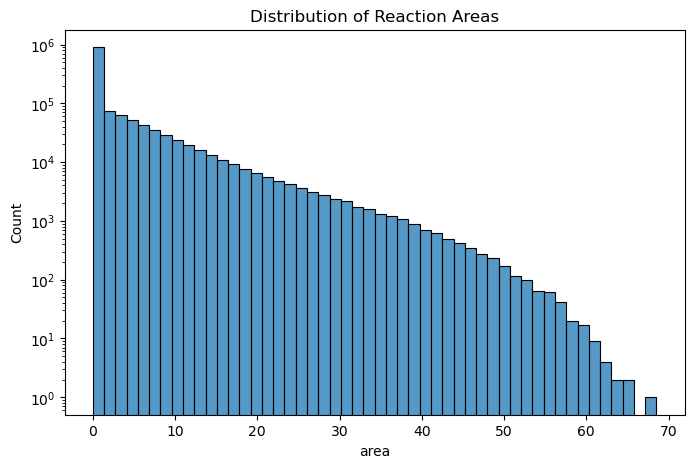

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(df["area"], bins=50)
plt.yscale("log")
plt.title("Distribution of Reaction Areas")
plt.show()

<Axes: xlabel='catalyst name', ylabel='area'>

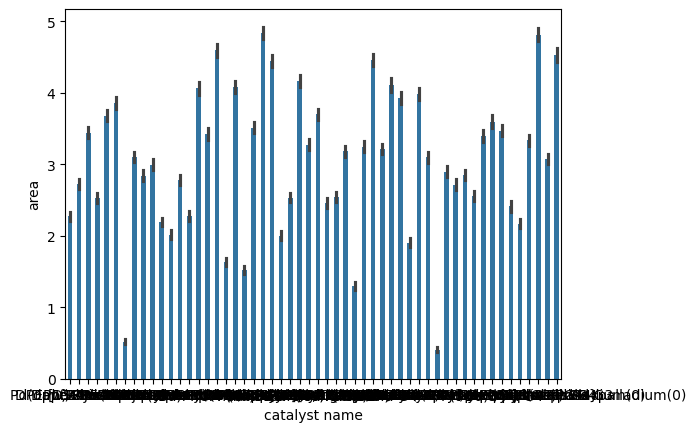

In [12]:
sns.barplot(data=df, y="area", x="catalyst name", width=0.5)

In [13]:
catalyst_avg = (
    df.groupby("catalyst name")["area"]
    .quantile(1) #Needs Clearification
    .sort_values(ascending=False)
)

catalyst_avg

catalyst_avg

catalyst name
L7 Pd G4                                                           68.525954
rac-BINAP Pd G4                                                    64.800172
GPhos Pd G4                                                        64.507093
BrettPhos Pd G3                                                    64.054859
Pd-PEPPSI-IPent                                                    62.296072
CPhos Pd G3                                                        61.868762
cBRIDP Pd G4                                                       61.823157
QPhos Pd G4                                                        61.323932
t-BuXPhos Pd G3                                                    61.184232
t-BuBrettPhos Pd G3                                                60.790605
AlPhos2Pd2COD                                                      60.285670
RuPhos Pd G3                                                       60.242309
XPhos Pd G4                                                   

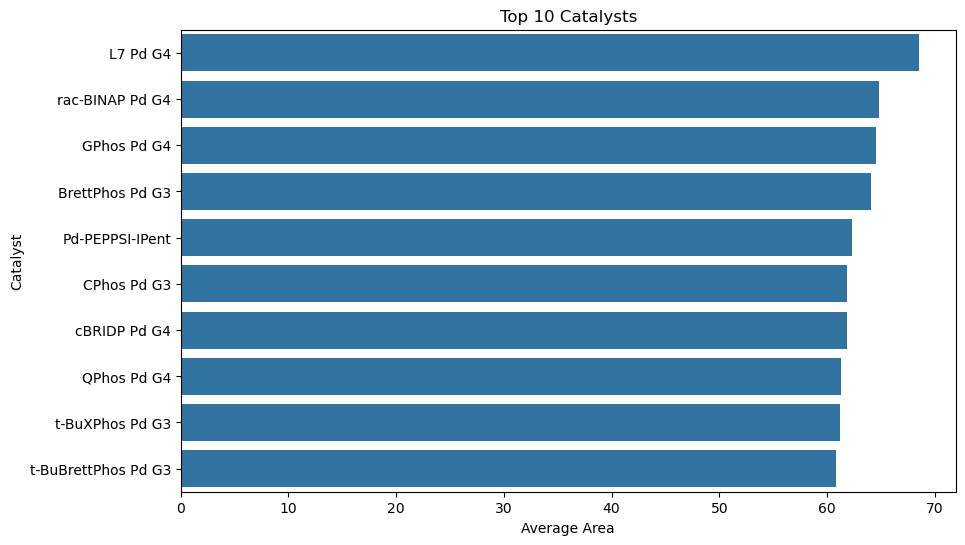

In [14]:
top10_catalysts = catalyst_avg.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top10_catalysts.values,
    y=top10_catalysts.index
)

plt.title("Top 10 Catalysts")
plt.xlabel("Average Area")
plt.ylabel("Catalyst")

plt.show()

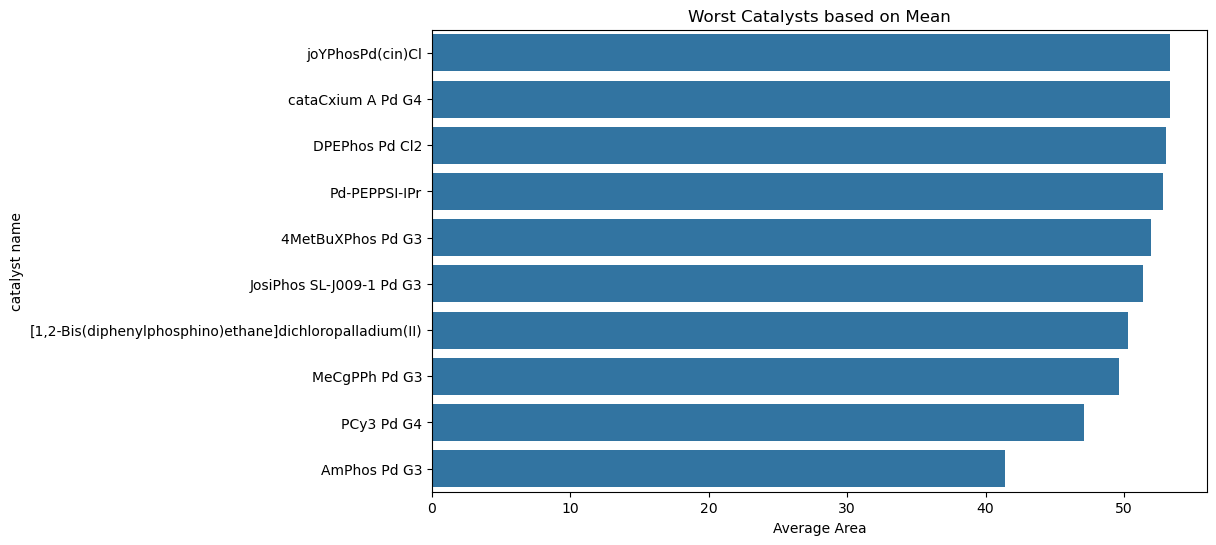

In [15]:
worst10_catalysts = catalyst_avg.tail(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=worst10_catalysts.values,
    y=worst10_catalysts.index
)

plt.title("Worst Catalysts based on Mean")
plt.xlabel("Average Area")

plt.show()

In [16]:
base_avg = (
    df.groupby("base name")["area"]
    .mean()
    .sort_values(ascending=False)
)

base_avg

base name
Sodium tert-pentoxide                                                                 5.418622
Cesium fluoride                                                                       4.406899
Potassium carbonate                                                                   4.183196
Potassium phenoxide                                                                   4.154101
Sodium bicarbonate                                                                    4.070606
Potassium phosphate tribasic                                                          4.035859
Sodium phenoxide                                                                      3.635394
Cesium carbonate                                                                      3.501783
BEMP (2-tert-Butylimino-2-diethylamino-1,3-dimethylperhydro-1,3,2-diazaphosphorine    3.331730
Sodium tert-butoxide                                                                  3.265156
Potassium hydroxide                     

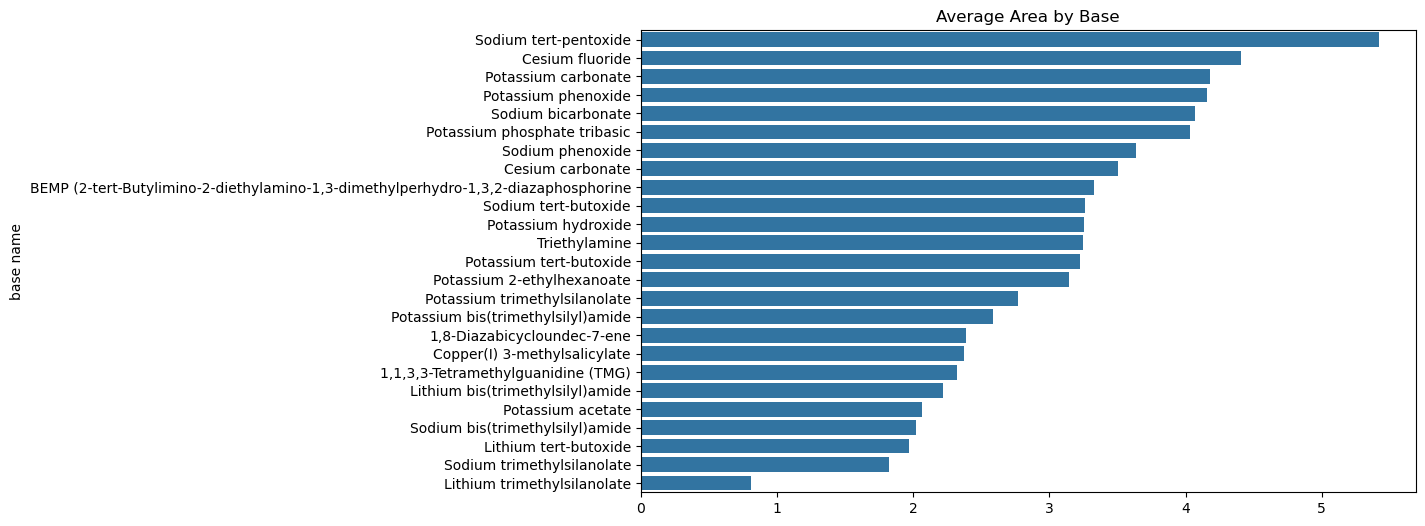

In [17]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=base_avg.values,
    y=base_avg.index
)

plt.title("Average Area by Base")

plt.show()

In [18]:
solvent_avg = (
    df.groupby("solvent name")["area"]
    .mean()
    .sort_values(ascending=False)
)

solvent_avg

solvent name
N,N-Dimethylformamide      5.444744
Acetonitrile               4.059981
2-Methyltetrahydrofuran    3.897923
1,2-Dimethoxyethane        3.518172
Ethyl acetate              3.394447
1,4-Dioxane                3.029089
2-Methyl-2-butanol         2.637732
N,N-Dimethylacetamide      2.630660
Anisole                    2.412216
Tetrahydrofuran            2.308655
Toluene                    1.964881
Dimethyl sulfoxide         1.285513
Name: area, dtype: float64

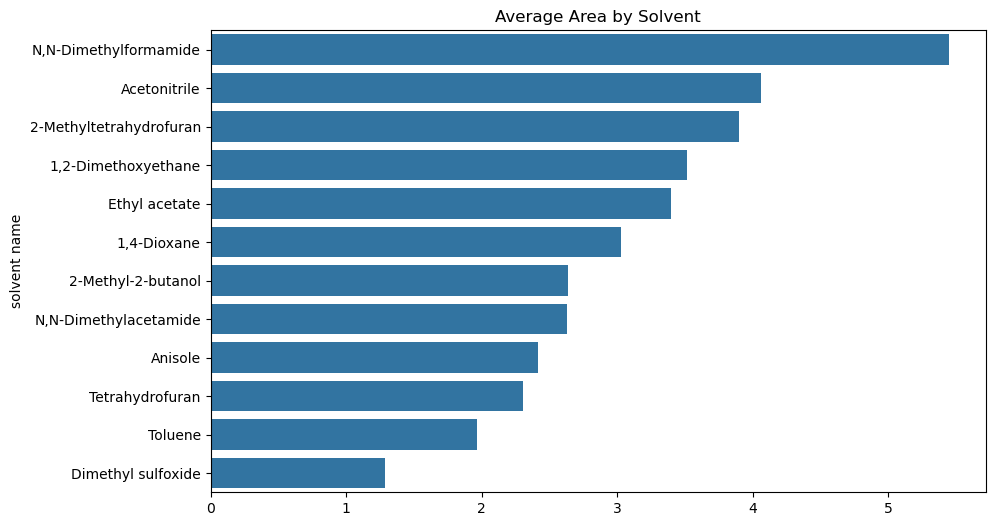

In [19]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=solvent_avg.values,
    y=solvent_avg.index
)

plt.title("Average Area by Solvent")

plt.show()

In [20]:
product_avg = (
    df.groupby("product")["area"]
    .mean()
    .sort_values(ascending=False)
)

product_avg

product
72521482    29.948938
bb6b148d    24.241012
da3d0a5a    15.490161
5d4fc05f    14.901040
b5bc2947    14.096416
              ...    
9a0fd7f1     0.000000
b32d7c38     0.000000
b6c72d20     0.000000
c8b8c9a0     0.000000
e4ea4667     0.000000
Name: area, Length: 83, dtype: float64

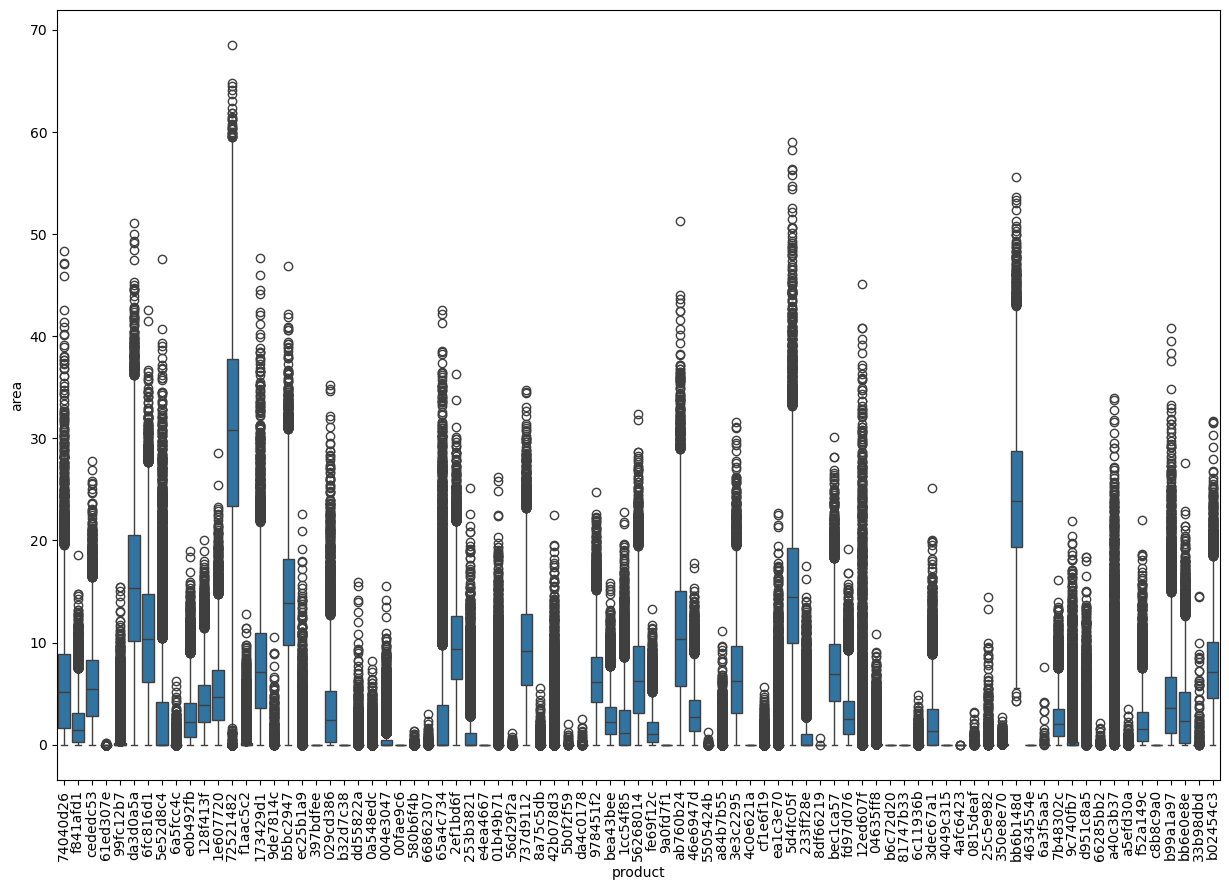

In [21]:
plt.figure(figsize=(15,10))

sns.boxplot(
    data=df,
    x="product",
    y="area"
)

plt.xticks(rotation=90)

plt.show()

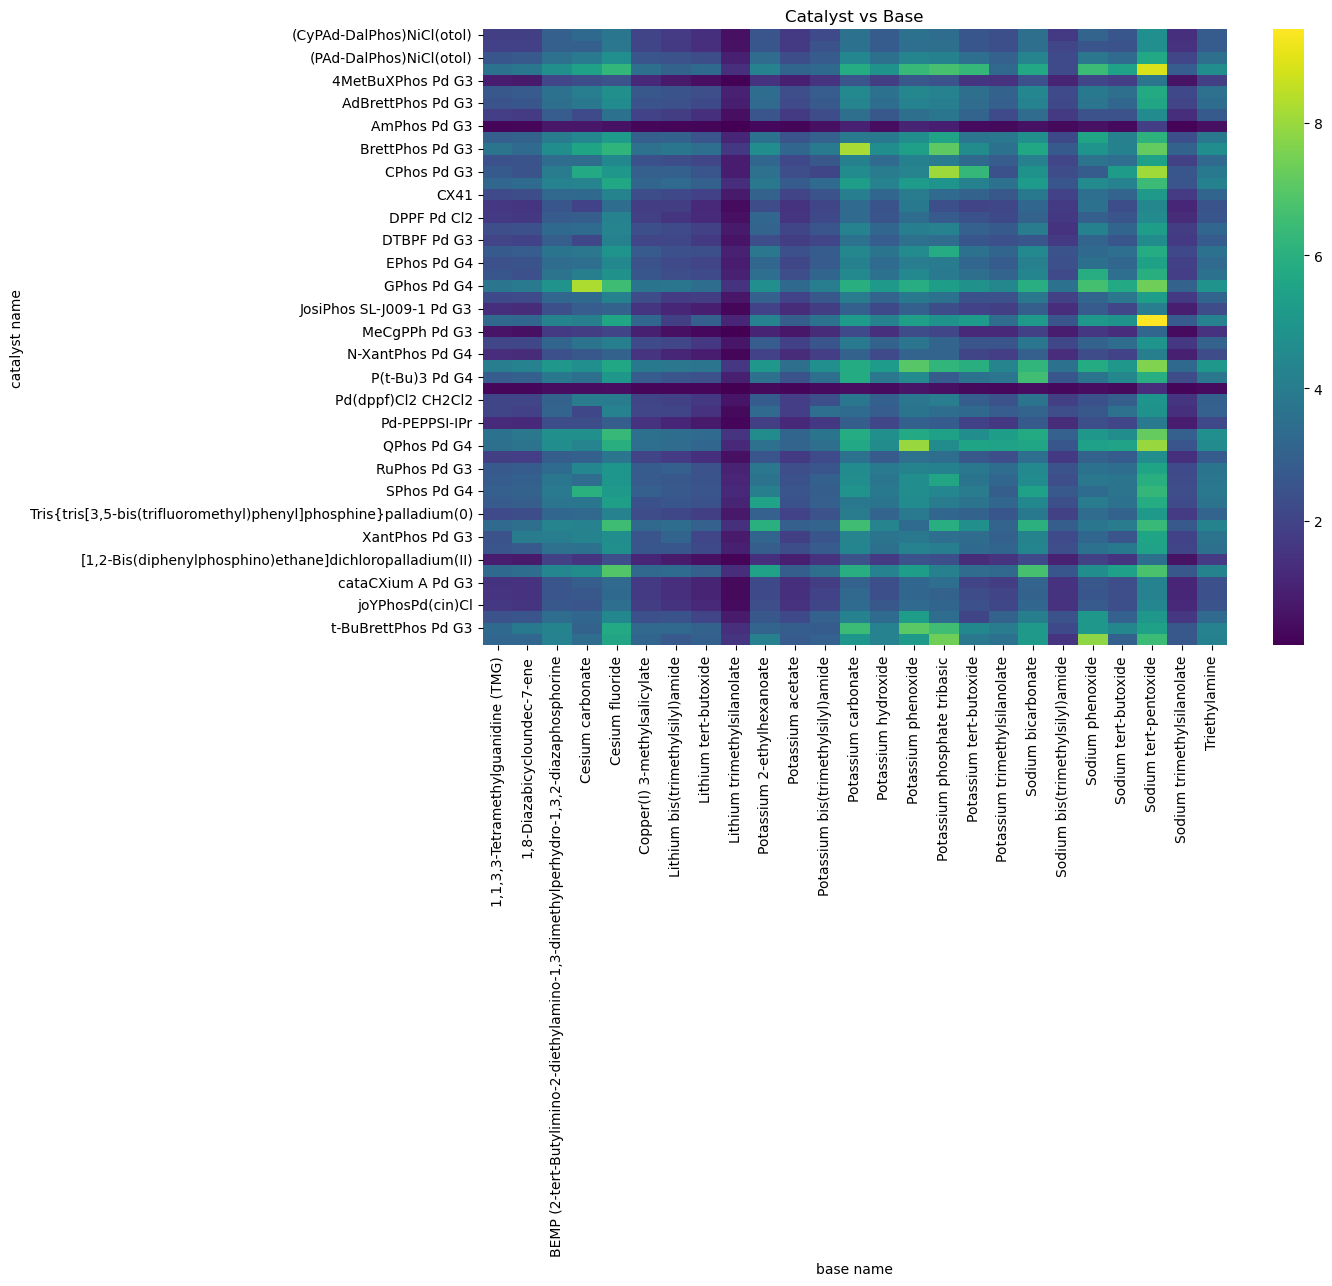

In [22]:
heatmap_data = pd.pivot_table(
    df,
    values="area",
    index="catalyst name",
    columns="base name",
    aggfunc="mean"
)

plt.figure(figsize=(12,8))

sns.heatmap(
    heatmap_data,
    cmap="viridis"
)

plt.title("Catalyst vs Base")

plt.show()

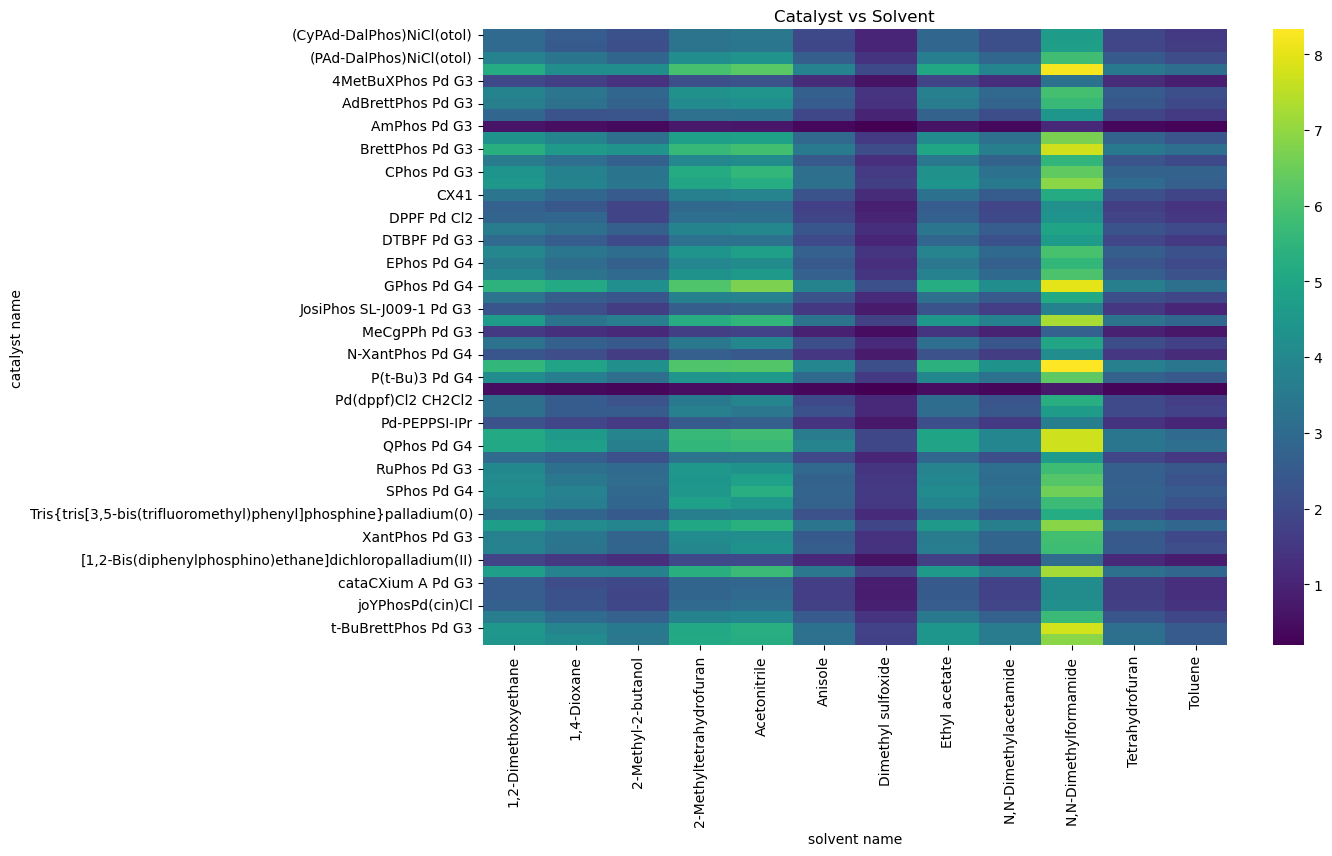

In [23]:
heatmap_data = pd.pivot_table(
    df,
    values="area",
    index="catalyst name",
    columns="solvent name",
    aggfunc="mean"
)

plt.figure(figsize=(12,8))

sns.heatmap(
    heatmap_data,
    cmap="viridis"
)

plt.title("Catalyst vs Solvent")

plt.show()

In [24]:
best_combinations = (
    df.sort_values("area", ascending=False)
    [["product",
      "catalyst name",
      "base name",
      "solvent name",
      "area"]]
)

best_combinations.head(10)

,product,catalyst name,base name,solvent name,area
199919,72521482,L7 Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",68.525954
206183,72521482,rac-BINAP Pd G4,Sodium phenoxide,"N,N-Dimethylformamide",64.800172
209987,72521482,GPhos Pd G4,Cesium carbonate,"N,N-Dimethylformamide",64.507093
210575,72521482,BrettPhos Pd G3,Potassium carbonate,"N,N-Dimethylformamide",64.054859
206231,72521482,rac-BINAP Pd G4,Potassium phenoxide,"N,N-Dimethylformamide",63.708232
199912,72521482,L7 Pd G4,Sodium tert-pentoxide,Acetonitrile,63.036139
207119,72521482,Pd-PEPPSI-IPent,Sodium tert-pentoxide,"N,N-Dimethylformamide",62.296072
195959,72521482,CPhos Pd G3,Potassium phosphate tribasic,"N,N-Dimethylformamide",61.868762
202163,72521482,cBRIDP Pd G4,Cesium fluoride,"N,N-Dimethylformamide",61.823157
199911,72521482,L7 Pd G4,Sodium tert-pentoxide,2-Methyltetrahydrofuran,61.452287


In [25]:
product_name = df["product"].iloc[0]

product_df = df[df["product"] == product_name]

In [26]:
best_catalysts = (
    product_df
    .groupby("catalyst name")["area"]
    .mean()
    .sort_values(ascending=False)
    .head(12)
)

best_catalysts

catalyst name
t-BuBrettPhos Pd G3        22.075742
BrettPhos Pd G3            10.267050
GPhos Pd G4                10.084279
QPhos Pd (crotyl)Cl         9.931130
(tBu)PhCPhos Pd G4          9.857308
QPhos Pd G4                 9.597869
cBRIDP Pd G4                8.816276
CPhos Pd G4                 8.757493
t-BuXPhos Pd G3             8.696900
L7 Pd G4                    8.614075
BippyPhos Pd(allyl) OTf     8.072836
CPhos Pd G3                 7.997912
Name: area, dtype: float64

In [27]:
best_bases = (
    product_df
    .groupby("base name")["area"]
    .mean()
    .sort_values(ascending=False)
    .head(2)
)

best_bases

base name
Sodium tert-pentoxide    11.966136
Potassium carbonate       9.141947
Name: area, dtype: float64

In [28]:
best_solvents = (
    product_df
    .groupby("solvent name")["area"]
    .mean()
    .sort_values(ascending=False)
    .head(2)
)

best_solvents

solvent name
N,N-Dimethylformamide    11.568305
Acetonitrile              8.220206
Name: area, dtype: float64

In [29]:
print("Recommended Catalysts:")
print(best_catalysts.index.tolist())

print("\nRecommended Bases:")
print(best_bases.index.tolist())

print("\nRecommended Solvents:")
print(best_solvents.index.tolist())

Recommended Catalysts:
['t-BuBrettPhos Pd G3', 'BrettPhos Pd G3', 'GPhos Pd G4', 'QPhos Pd (crotyl)Cl', '(tBu)PhCPhos Pd G4', 'QPhos Pd G4', 'cBRIDP Pd G4', 'CPhos Pd G4', 't-BuXPhos Pd G3', 'L7 Pd G4', 'BippyPhos Pd(allyl) OTf', 'CPhos Pd G3']

Recommended Bases:
['Sodium tert-pentoxide', 'Potassium carbonate']

Recommended Solvents:
['N,N-Dimethylformamide', 'Acetonitrile']


In [30]:
# Select the area values for the product stored in product_name
df.groupby("product").get_group(product_name)["area"].to_numpy()[0]

np.float64(0.5314139565109126)

In [31]:
df["catalyst name"].unique()

array(['DPEPhos Pd Cl2', 'Pd(dppf)Cl2 CH2Cl2', 'DavePhos Pd G3',
       'DTBPF Pd G3', 'SPhos Pd G4', 'CPhos Pd G3', 'AmPhos Pd G3',
       'BrettPhos Pd G4', 'JackiePhos Pd G3', 'DTBNpP Pd G3',
       'cataCxium A Pd G4', 'N-XantPhos Pd G4', 'MorDalPhos Pd G4',
       'joYPhosPd(cin)Cl', 't-BuBrettPhos Pd G3', 'RuPhos Pd G3',
       '(tBu)PhCPhos Pd G4', '4MetBuXPhos Pd G3', 'L7 Pd G4',
       '[1,2-Bis(diphenylphosphino)ethane]dichloropalladium(II)',
       'RuPhos Pd G4', 'P(Ad)3 Pd G4', 'QPhos Pd (crotyl)Cl',
       'JosiPhos SL-J009-1 Pd G3', 'RockPhos Pd G3', 'cBRIDP Pd G4',
       '(PAd-DalPhos)NiCl(otol)', 'BippyPhos Pd(allyl) OTf',
       'AlPhos2Pd2COD', '(PAPPdG6)2', 'AdBrettPhos Pd G3',
       'MeCgPPh Pd G3', 'XantPhos Pd G4', 'QPhos Pd G4', 'XantPhos Pd G3',
       'XPhos Pd G4', 'CPhos Pd G4', 'Pd-PEPPSI-IPr', 't-BuXPhos Pd G3',
       'rac-BINAP Pd G4', 'PCy3 Pd G4', 'CX41', 'Pd-PEPPSI-IPent',
       'Tris{tris[3,5-bis(trifluoromethyl)phenyl]phosphine}palladium(0)',
   

In [32]:
np.sort(df["catalyst name"].unique())

array(['(CyPAd-DalPhos)NiCl(otol)', '(PAPPdG6)2',
       '(PAd-DalPhos)NiCl(otol)', '(tBu)PhCPhos Pd G4',
       '4MetBuXPhos Pd G3', 'AdBippyPhos Pd G4', 'AdBrettPhos Pd G3',
       'AlPhos2Pd2COD', 'AmPhos Pd G3', 'BippyPhos Pd(allyl) OTf',
       'BrettPhos Pd G3', 'BrettPhos Pd G4', 'CPhos Pd G3', 'CPhos Pd G4',
       'CX41', 'DPEPhos Pd Cl2', 'DPPF Pd Cl2', 'DTBNpP Pd G3',
       'DTBPF Pd G3', 'DavePhos Pd G3', 'EPhos Pd G4', 'GPhos Pd G3',
       'GPhos Pd G4', 'JackiePhos Pd G3', 'JosiPhos SL-J009-1 Pd G3',
       'L7 Pd G4', 'MeCgPPh Pd G3', 'MorDalPhos Pd G4',
       'N-XantPhos Pd G4', 'P(Ad)3 Pd G4', 'P(t-Bu)3 Pd G4', 'PCy3 Pd G4',
       'Pd(dppf)Cl2 CH2Cl2', 'Pd-PEPPSI-IPent', 'Pd-PEPPSI-IPr',
       'QPhos Pd (crotyl)Cl', 'QPhos Pd G4', 'RockPhos Pd G3',
       'RuPhos Pd G3', 'RuPhos Pd G4', 'SPhos Pd G4',
       'Tetrakis(triphenylphosphine)palladium(0)',
       'Tris{tris[3,5-bis(trifluoromethyl)phenyl]phosphine}palladium(0)',
       'XPhos Pd G4', 'XantPhos Pd G3', 

In [33]:
recommended_catalysts = sorted(best_catalysts.index.tolist())
print(recommended_catalysts)

['(tBu)PhCPhos Pd G4', 'BippyPhos Pd(allyl) OTf', 'BrettPhos Pd G3', 'CPhos Pd G3', 'CPhos Pd G4', 'GPhos Pd G4', 'L7 Pd G4', 'QPhos Pd (crotyl)Cl', 'QPhos Pd G4', 'cBRIDP Pd G4', 't-BuBrettPhos Pd G3', 't-BuXPhos Pd G3']


In [34]:
recommended_bases = sorted(best_bases.index.tolist())
print(recommended_bases)

['Potassium carbonate', 'Sodium tert-pentoxide']


In [35]:
recommended_solvents = sorted(best_solvents.index.tolist())
print(recommended_solvents)

['Acetonitrile', 'N,N-Dimethylformamide']


In [36]:
#Find out which triplets hase the best reaction area with the different prodicts

In [37]:
df[
    (df["catalyst name"] == recommended_catalysts[0])
    & (df["solvent name"] == recommended_solvents[0])
    & (df["base name"] == recommended_bases[0])
]
#This is the first triplet with the best reaction area for the product stored in product_name. You can repeat this process for other products by changing the value of product_name.

,product,catalyst name,base name,solvent name,area
5068,74040d26,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,17.247907
21268,f841afd1,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,7.836165
37468,cededc53,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,14.722620
53668,61ed307e,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,0.000000
69868,99fc12b7,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,5.131826
...,...,...,...,...,...
1268668,c8b8c9a0,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,0.000000
1284868,b99a1a97,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,10.224635
1301068,bb6e0e8e,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,8.099506
1317268,33b98dbd,(tBu)PhCPhos Pd G4,Potassium carbonate,Acetonitrile,0.000000


In [38]:
#Now i have to find out the best triplet for the other products. ( I will create a function that takes the product name as input and returns the best triplet for that poduct.)
#so below i am doing average first and then rank

In [39]:
#Cell 1 of ELO Ranking
triplets_df = (
    df.groupby(
        ["catalyst name", "base name", "solvent name"]
    )["area"]
    .mean()
    .reset_index()
    .sort_values("area", ascending=False)
)
triplets_df = triplets_df.head(100).copy()
triplets_df

,catalyst name,base name,solvent name,area
7773,L7 Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",15.430365
1173,(tBu)PhCPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",14.796323
3153,BrettPhos Pd G3,Potassium carbonate,"N,N-Dimethylformamide",13.233406
11073,QPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",12.981790
6645,GPhos Pd G4,Cesium carbonate,"N,N-Dimethylformamide",12.976806
...,...,...,...,...
15849,t-BuBrettPhos Pd G3,Sodium phenoxide,"N,N-Dimethylformamide",9.620072
13473,XantPhos Pd G3,Sodium tert-pentoxide,"N,N-Dimethylformamide",9.620058
15825,t-BuBrettPhos Pd G3,Sodium bicarbonate,"N,N-Dimethylformamide",9.619384
10953,QPhos Pd G4,Potassium carbonate,"N,N-Dimethylformamide",9.615212


In [40]:
from itertools import combinations

elo = {
    idx: 1500
    for idx in triplets_df.index
}

K = 32


In [41]:
for a, b in combinations(triplets_df.index, 2):

    area_a = triplets_df.loc[a, "area"]
    area_b = triplets_df.loc[b, "area"]

    rating_a = elo[a]
    rating_b = elo[b]

    expected_a = 1 / (1 + 10 ** ((rating_b - rating_a) / 400))
    expected_b = 1 / (1 + 10 ** ((rating_a - rating_b) / 400))

    if area_a > area_b:
        score_a = 1
        score_b = 0
    elif area_b > area_a:
        score_a = 0
        score_b = 1
    else:
        score_a = 0.5
        score_b = 0.5

    elo[a] += K * (score_a - expected_a)
    elo[b] += K * (score_b - expected_b)


In [42]:
triplets_df["elo"] = triplets_df.index.map(elo)

triplets_df.head()

,catalyst name,base name,solvent name,area,elo
7773,L7 Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",15.430365,1988.329326
1173,(tBu)PhCPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",14.796323,1980.823153
3153,BrettPhos Pd G3,Potassium carbonate,"N,N-Dimethylformamide",13.233406,1973.392842
11073,QPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",12.981790,1966.019835
6645,GPhos Pd G4,Cesium carbonate,"N,N-Dimethylformamide",12.976806,1958.688186


In [43]:
#Cell 5
triplets_df = triplets_df.sort_values(
    "elo",
    ascending=False
)

triplets_df

,catalyst name,base name,solvent name,area,elo
7773,L7 Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",15.430365,1988.329326
1173,(tBu)PhCPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",14.796323,1980.823153
3153,BrettPhos Pd G3,Potassium carbonate,"N,N-Dimethylformamide",13.233406,1973.392842
11073,QPhos Pd G4,Sodium tert-pentoxide,"N,N-Dimethylformamide",12.981790,1966.019835
6645,GPhos Pd G4,Cesium carbonate,"N,N-Dimethylformamide",12.976806,1958.688186
...,...,...,...,...,...
15849,t-BuBrettPhos Pd G3,Sodium phenoxide,"N,N-Dimethylformamide",9.620072,852.171518
13473,XantPhos Pd G3,Sodium tert-pentoxide,"N,N-Dimethylformamide",9.620058,831.458338
15825,t-BuBrettPhos Pd G3,Sodium bicarbonate,"N,N-Dimethylformamide",9.619384,810.528778
10953,QPhos Pd G4,Potassium carbonate,"N,N-Dimethylformamide",9.615212,789.384578


In [44]:
len(triplets_df)

100

In [ ]:
# Github Repo
import subprocess
import time

# Wait 1 second to make sure VS Code Auto Save finishes writing your file to disk
time.sleep(1)

commit_message = "Update Buchwald reaction analysis and Elo rankings"
cmd = f'git add . && git commit -m "{commit_message}" && git push'

result = subprocess.run(cmd, shell=True, capture_output=True, text=True)
print("OUTPUT:\n", result.stdout)
if result.stderr:
    print("STATUS/ERRORS:\n", result.stderr)